In [ ]:
# 그래프 관련 import
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
# matplotlib.rcParams['font.family'] = 'AppleGothic'
matplotlib.rcParams['axes.unicode_minus']=False

# 판다스 관련 import
import pandas as pd
import numpy as np

# 인공지능 import
from sklearn import svm,metrics
from sklearn.neighbors import KNeighborsClassifier  #분류
from sklearn.neighbors import KNeighborsRegressor   #예측
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures # 다항특성 자동생성 라이브러리
from sklearn.linear_model import Ridge              #릿지
from sklearn.linear_model import Lasso              #라쏘

from sklearn.metrics import mean_absolute_error # 평균절대값오차 오차범위
from sklearn.preprocessing import StandardScaler # 정규화 클래스
from sklearn.model_selection import train_test_split

In [35]:
df= pd.read_csv('data/perch_full.csv')
df.head(2)

,length,height,width
0,8.4,2.11,1.41
1,13.7,3.53,2.00


In [36]:
# 무게 데이터 (label)
perch_weight = [5.9, 32.0, 40.0, 51.5, 70.0, 100.0, 78.0, 80.0, 85.0, 85.0,
    110.0, 115.0, 125.0, 130.0, 120.0, 120.0, 130.0, 135.0, 110.0,
    130.0, 150.0, 145.0, 150.0, 170.0, 225.0, 145.0, 188.0, 180.0,
    197.0, 218.0, 300.0, 260.0, 265.0, 250.0, 250.0, 300.0, 320.0,
    514.0, 556.0, 840.0, 685.0, 700.0, 700.0, 690.0, 900.0, 650.0,
    820.0, 850.0, 900.0, 1015.0, 820.0, 1100.0, 1000.0, 1100.0,
    1000.0, 1000.0]

In [37]:
# 데이터 전처리

# 학습/ 테스트 데이터 분리
train_data, test_data, train_label, test_label= train_test_split(df,perch_weight,random_state=42)

In [38]:
train_data[:2]

,length,height,width
8,19.6,5.14,3.04
17,22.0,5.88,3.52


In [39]:
# 특성값추가
poly = PolynomialFeatures(degree=2, include_bias=False) #기본값 1제외
poly.fit(train_data)
train_poly = poly.transform(train_data)
test_poly =  poly.transform(test_data)

In [40]:
poly.get_feature_names_out()

array(['length', ' height', ' width', 'length^2', 'length  height',
       'length  width', ' height^2', ' height  width', ' width^2'],
      dtype=object)

In [41]:
# 규제 정규화
ss=StandardScaler()
ss.fit(train_poly)
train_scaler = ss.transform(train_poly)
test_scaler = ss.transform(test_poly)

In [44]:
# 라쏘규제
alpha_list =[0.001,0.01,0.1,1,10,100]
train_score=[]
test_score=[]
for alpha in alpha_list:
    lasso= Lasso(alpha=alpha)
    lasso.fit(train_scaler, train_label)

    score= lasso.score(train_scaler, train_label)
    score2= lasso.score(test_scaler, test_label)

    train_score.append(score)
    test_score.append(score2)



c:\python313\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.902820e+04, tolerance: 5.183e+02
  model = cd_fast.enet_coordinate_descent(
c:\python313\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.685690e+04, tolerance: 5.183e+02
  model = cd_fast.enet_coordinate_descent(
c:\python313\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.545601e+03, tolerance: 5.183e+02
  model = cd_f

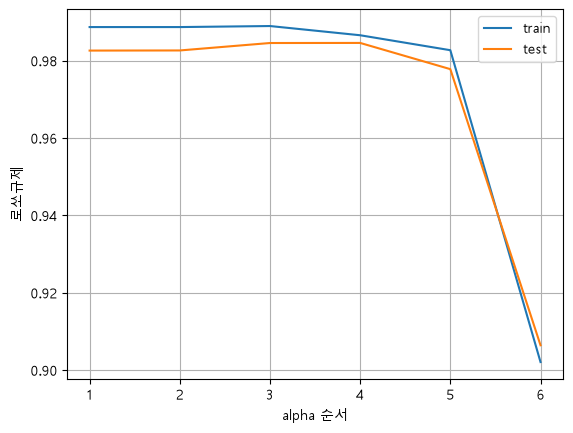

In [ ]:
no_list=list(range(1,7))
plt.plot(no_list, train_score)
plt.plot(no_list, test_score)

plt.grid()

plt.legend(['train','test'])

plt.xlabel('alpha 순서')
plt.ylabel('로쏘규제')
plt.show()

In [ ]:
lasso= Lasso(alpha=1)
lasso.fit(train_scaler, train_label)

score= lasso.score(train_scaler, train_label)
score2= lasso.score(test_scaler, test_label)

print('train 정확도 : ',score)
print('test 정확도 : ',score2)
print(np.sum(lasso.coef_))      #사용하지 않는 특성이 있음.->릿지규제를 더 많이 사용한다

train 정확도 :  0.986591255464559
test 정확도 :  0.9846056618190412
348.8739468575063


In [43]:
lr= LinearRegression()
lr.fit(train_poly, train_label)
score= lr.score(train_poly, train_label)
score2=lr.score(test_poly, test_label)

print('train 정확도 : ',score)
print('test 정확도 : ',score2)

train 정확도 :  0.9903183436982124
test 정확도 :  0.9714559911594145
